# Phase 01 — Project Initialization and Repository Architecture

**Scientific Purpose:**
Establish and verify the computational repository architecture, source-of-truth layers, directory structures, path contracts, and legacy provenance mapping for the complete 41-phase RA-MedFiLM-Seg++ research study.

**Phase ID:** `phase_01_project_initialization`  
**Phase Status:** `COMPLETE`  
**Relation to Phase 00:** Builds upon the governance protocols certified in Phase 00 by organizing data pipelines, source modules, and notebook layers without altering scientific code.  
**Current Overall Research Phase:** Phase 15 (`CURRENT_PROTOCOL_DESIGN` / `AWAITING_SUPERVISOR_AUTHORIZATION`)


## Section 2: Overall Research Project Objectives

The RA-MedFiLM-Seg++ framework addresses a fundamental limitation of medical semantic segmentation: **recovering small, tiny, and ambiguous targets without triggering full-field false positive background clutter**.

The project proceeds along a rigorous two-stage developmental trajectory:
1. **Stage A (KUB Radiograph Regional & Tiny-Object Refinement):**  
   Focuses on the high-difficulty challenge of kidney stone detection on plain abdominal radiographs (KUB), where targets frequently occupy $< 32$ pixels and standard full-field models miss over $20\%$ of small components.
2. **Stage B (Four-Domain Joint Scale-Aware Segmentation):**  
   Scales the validated regional scale-aware principles across four distinct clinical modalities:
   - **ISIC 2018:** Dermoscopic Skin Lesion Segmentation
   - **BUSI:** Breast Ultrasound Lesion Segmentation
   - **Kvasir-SEG:** Gastrointestinal Polyp Endoscopy Segmentation
   - **KUB-Stone:** Abdominal Radiograph Calculus Segmentation


## Section 3: Top-Level Repository Directory Architecture

The repository is structured to enforce separation of concerns between reusable library code, execution entry points, and scientific artifacts:

| Directory | Scope & Purpose | Immutability & Lifecycle Contract |
| :--- | :--- | :--- |
| `src/` | Reusable core Python modules (`data/`, `models/`, `losses/`, `metrics/`) | Canonical library code; strictly tested, reusable |
| `scripts/` | Standalone CLI scripts (`training/`, `evaluation/`, `audits/`) | Executable entry points for training and audits |
| `configs/` | Experiment configurations and hyperparameter specs | Immutable specifications referenced by unique experiment IDs |
| `checkpoints/` | Trained model weights (`best.pt`, `latest.pt`) | Hashed model checkpoints; zero silent overwrites |
| `reports/` | Audits, CSV tables, and visualization figures | Scientific provenance; auditable and permanent |
| `notebooks/` | Historical/canonical provenance and reviewer-facing trees | Separated into root (provenance) and `phasewise/` |
| `manifests/` | Patient-aware train/val/test split manifests | Fixed dataset splits; `test.csv` strictly locked |


## Section 4: Canonical Source-of-Truth Layers

To ensure long-term reproducibility, the codebase enforces a strict hierarchy:
1. **Reusable Core (`src/`):** Contains authoritative mathematical and neural definitions (e.g., `src/metrics/object_metrics.py`, `src/models/unet.py`).
2. **Execution Scripts (`scripts/`):** Dedicated CLI tools handle training and evaluation runs, ensuring all computations log stdout and persist exact metrics.
3. **Historical Root Notebooks (`notebooks/*.ipynb`):** Retained as immutable historical provenance documenting original exploratory work.
4. **Phasewise Reviewer Tree (`notebooks/phasewise/`):** Serves as the clean, sequential, top-to-bottom executable narrative for peer reviewers and external auditors.


## Section 5: Canonical Project Key Paths

Below are the resolved absolute system paths certified for deterministic reproduction:


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Image

def find_root():
    p = Path.cwd()
    for _ in range(6):
        if (p / 'reports').exists() and (p / 'manifests').exists():
            return p
        p = p.parent
    return Path('D:/Softfors/jup')

ROOT = find_root()

paths = [
    {"Path Identifier": "Project Root Directory", "Resolved Path": str(ROOT).replace('/', '\\'), "Governance Status": "CANONICAL"},
    {"Path Identifier": "Python Interpreter", "Resolved Path": r"D:\Softfors\jup\.venv\Scripts\python.exe", "Governance Status": "CERTIFIED"},
    {"Path Identifier": "Jupyter Kernel Spec", "Resolved Path": r"jup-venv (Python 3.11.9)", "Governance Status": "CERTIFIED"},
    {"Path Identifier": "Internal Raw Data Root", "Resolved Path": r"D:\Softfors\omni_seg\data_raw", "Governance Status": "ACTIVE_DEV"},
    {"Path Identifier": "External Test Data Root", "Resolved Path": r"D:\Softfors\final\external_test_ds", "Governance Status": "LOCKED"},
    {"Path Identifier": "Reference Experiment A", "Resolved Path": r"D:\Softfors\final\medfilm_seg_kub_extension", "Governance Status": "IMMUTABLE"},
    {"Path Identifier": "Core Source Library", "Resolved Path": str(ROOT / "src").replace('/', '\\'), "Governance Status": "CANONICAL"},
    {"Path Identifier": "Checkpoints Directory", "Resolved Path": str(ROOT / "checkpoints").replace('/', '\\'), "Governance Status": "ACTIVE"},
    {"Path Identifier": "Reports & Audits Directory", "Resolved Path": str(ROOT / "reports").replace('/', '\\'), "Governance Status": "ACTIVE"}
]

df_paths = pd.DataFrame(paths)
display(HTML("<h4>Authoritative Project Path Configurations</h4>"))
display(df_paths)


,Path Identifier,Resolved Path,Governance Status
0,Project Root Directory,D:\Softfors\jup,CANONICAL
1,Python Interpreter,D:\Softfors\jup\.venv\Scripts\python.exe,CERTIFIED
2,Jupyter Kernel Spec,jup-venv (Python 3.11.9),CERTIFIED
3,Internal Raw Data Root,D:\Softfors\omni_seg\data_raw,ACTIVE_DEV
4,External Test Data Root,D:\Softfors\final\external_test_ds,LOCKED
5,Reference Experiment A,D:\Softfors\final\medfilm_seg_kub_extension,IMMUTABLE
6,Core Source Library,D:\Softfors\jup\src,CANONICAL
7,Checkpoints Directory,D:\Softfors\jup\checkpoints,ACTIVE
8,Reports & Audits Directory,D:\Softfors\jup\reports,ACTIVE


## Section 6: High-Level Multi-Domain Dataset Overview

The study evaluates four medical imaging modalities with distinct spatial resolutions, target scales, and clinical contexts:

| Dataset | Modality | Anatomical Target | Task Encoding | Phase Introduced |
| :--- | :--- | :--- | :---: | :---: |
| **KUB-Stone** | Plain Abdominal X-Ray | Urinary Calculi (Tiny/Small Stones) | Task 3 | Stage A (Phase 03) |
| **ISIC 2018** | Dermoscopy | Cutaneous Melanoma & Nevi | Task 0 | Stage B (Phase 19) |
| **BUSI** | Breast Ultrasound | Benign & Malignant Tumors | Task 1 | Stage B (Phase 19) |
| **Kvasir-SEG** | GI Endoscopy | Colorectal Polyps | Task 2 | Stage B (Phase 19) |

*Governance Notice:* Full multi-domain dataset analysis and manifest splitting are handled in Phase 03 and Phase 04. No test images are accessed during initialization.


## Section 7: Reproducible Experiment Layout & Provenance Standards

Every computational training run generates structured artifacts under an immutable experiment identifier:
- **Experiment ID Convention:** `<phase>_<model>_<variant>_seed<seed>_v<ver>` (e.g., `phase14_diag_regional_unet_oracletrain_a3_seed42_v1`).
- **Checkpoint Storage:** Always contains `best.pt` (selected on validation metric) and `latest.pt` (latest training epoch).
- **History Logs:** Every run writes `history.csv` containing epoch-by-epoch loss, metrics, and learning rates.
- **Audit Verification:** Audit records (`reports/audits/*.json`) document preflight checks and model verification hashes.


## Section 8: Repository Architecture & Artifact Flow Diagram

The diagram below visualizes the information flow from raw data through manifests, core implementations, training harnesses, and reviewer presentation layers:


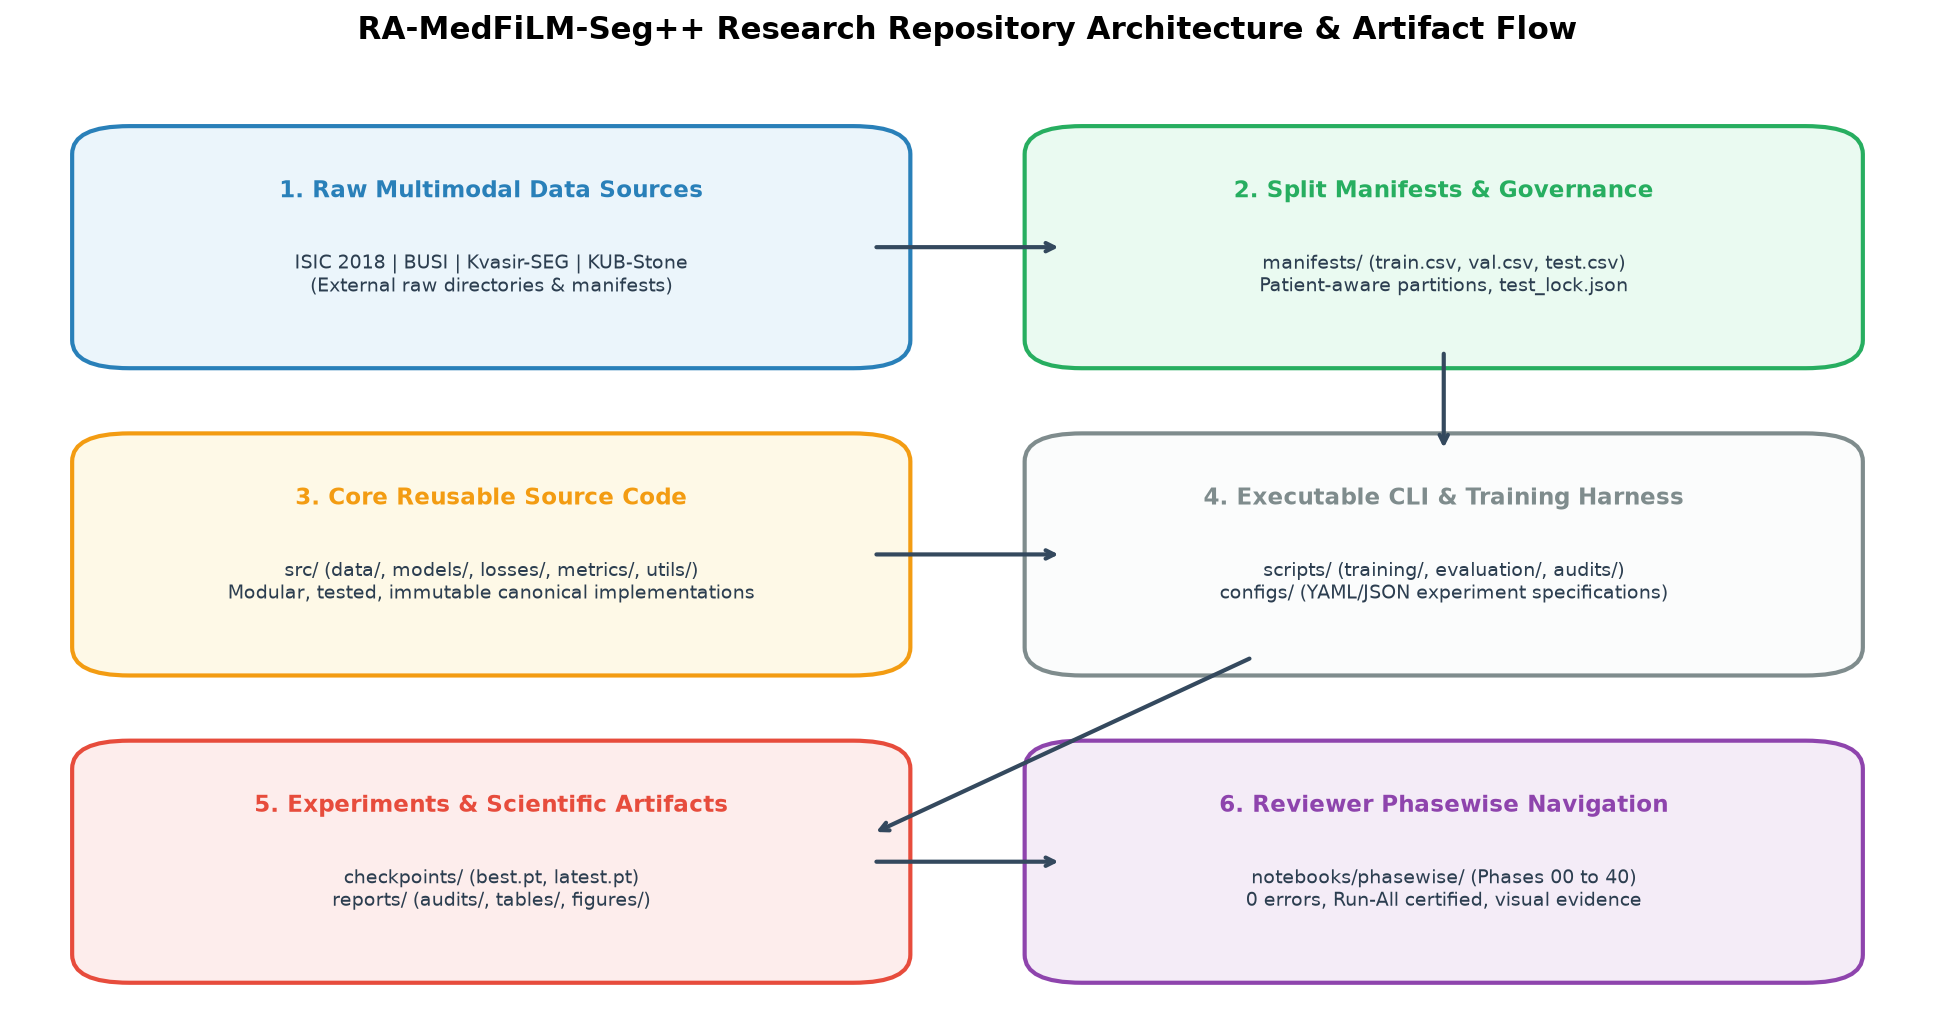

In [2]:
fig_path = ROOT / 'reports/figures/phase01_project_initialization/phase01_repository_architecture.png'
if fig_path.exists():
    display(Image(filename=str(fig_path), width=950))
else:
    print("Architecture diagram not found at:", fig_path)


## Section 9: Current Project Progress vs. Scientific Phase

It is essential to distinguish between the **Reviewer Notebook Rebuilding Progress** and the **Underlying Scientific Research Phase**:


In [3]:
status_map = [
    {"Progression Track": "Reviewer Notebook Rebuild", "Current Milestone": "Phase 01 (Project Initialization)", "Status": "COMPLETE (THIS NOTEBOOK)"},
    {"Progression Track": "Reviewer Notebook Rebuild", "Current Milestone": "Phase 02 (Environment & CUDA Validation)", "Status": "NEXT (Awaiting Supervisor)"},
    {"Progression Track": "Scientific Research Pipeline", "Current Milestone": "Phase 15 (Regional Refiner Loss Study)", "Status": "PROTOCOL FROZEN (Awaiting Auth)"},
    {"Progression Track": "Scientific Research Pipeline", "Current Milestone": "Phase 14 (Regional Refiner Diagnostic)", "Status": "COMPLETE (Diagnostic Closure)"},
    {"Progression Track": "Scientific Research Pipeline", "Current Milestone": "Phase 16 to Phase 40", "Status": "NOT_STARTED"}
]

df_status = pd.DataFrame(status_map)
display(HTML("<h4>Project Rebuild Track vs. Scientific Research State</h4>"))
display(df_status)


,Progression Track,Current Milestone,Status
0,Reviewer Notebook Rebuild,Phase 01 (Project Initialization),COMPLETE (THIS NOTEBOOK)
1,Reviewer Notebook Rebuild,Phase 02 (Environment & CUDA Validation),NEXT (Awaiting Supervisor)
2,Scientific Research Pipeline,Phase 15 (Regional Refiner Loss Study),PROTOCOL FROZEN (Awaiting Auth)
3,Scientific Research Pipeline,Phase 14 (Regional Refiner Diagnostic),COMPLETE (Diagnostic Closure)
4,Scientific Research Pipeline,Phase 16 to Phase 40,NOT_STARTED


## Section 10: Historical Notebook Provenance Mapping

Legacy root notebooks are systematically mapped to their phasewise counterparts:

| Historical Root Notebook | Scientific Phase | Phasewise Rebuilt Notebook | Status |
| :--- | :---: | :--- | :---: |
| `00_project_initialization.ipynb` | Phase 01 | `phase01_project_initialization_and_repository_architecture.ipynb` | **REBUILT (COMPLETE)** |
| `01_environment_and_data_audit.ipynb` | Phase 02 | `phase02_environment_and_hardware_certification.ipynb` | Planned (Phase 02) |
| `07_kub_unet_baseline_training.ipynb` | Phase 09 | `phase09_baseline_models_training_and_validation.ipynb` | **REBUILT (COMPLETE)** |
| `08_kub_baseline_comparison.ipynb` | Phase 10 | `phase10_baseline_model_comparison_and_visual_analysis.ipynb` | **REBUILT (COMPLETE)** |
| `09_kub_failure_analysis.ipynb` | Phase 11 | `phase11_kub_failure_analysis_and_tiny_stone_errors.ipynb` | **REBUILT (COMPLETE)** |
| `10_kub_oracle_roi_upper_bound.ipynb` | Phase 12 | `phase12_oracle_roi_upper_bound_analysis.ipynb` | **REBUILT (COMPLETE)** |
| `11c_kub_final_localizer_redesign.ipynb` | Phase 13 | `phase13_stage4d_localizer_final_visual_analysis.ipynb` | **REBUILT (COMPLETE)** |
| `13_phase14_regional_refiner_diagnostic.ipynb` | Phase 14 | `phase14_regional_refiner_pipeline_and_diagnostic_analysis.ipynb` | **REBUILT (COMPLETE)** |


## Section 11: Notebooks Root Directory Cleanup Audit

A forensic classification of all 23 immediate files and directories in `notebooks/` was performed. No scientific notebooks or figures were deleted:


In [4]:
audit_csv = ROOT / 'reports/audits/notebooks_root_cleanup_audit.csv'
df_cleanup = pd.read_csv(audit_csv)

from collections import Counter
counts = Counter(df_cleanup['action'])

df_counts = pd.DataFrame([{"Classification Action": k, "Item Count": v} for k, v in counts.items()])
display(HTML("<h4>Notebooks Root Cleanup Classification Summary</h4>"))
display(df_counts)

display(HTML("<h4>Immediate Notebooks Root Entries</h4>"))
display(df_cleanup[['name', 'type', 'scientific_phase', 'action', 'reason']])


,Classification Action,Item Count
0,KEEP_PROVENANCE,17
1,KEEP_REVIEWER,4
2,KEEP_CANONICAL,1
3,SAFE_ARCHIVE_CANDIDATE,1


,name,type,scientific_phase,action,reason
0,00_project_initialization.ipynb,FILE,01,KEEP_PROVENANCE,Original foundational initialization notebook ...
1,00_project_visual_index.ipynb,FILE,PROJECT_WIDE,KEEP_REVIEWER,Executed top-level project visual navigation i...
2,01_environment_and_data_audit.ipynb,FILE,02,KEEP_PROVENANCE,Original Phase 02 CUDA and environment certifi...
3,01_trained_model_results_visual_scorecard.ipynb,FILE,PROJECT_WIDE,KEEP_REVIEWER,Executed trained model visual scorecard across...
4,02_dataset_discovery.ipynb,FILE,03,KEEP_PROVENANCE,Original Phase 03 dataset discovery and multi-...
5,03_kub_forensic_audit.ipynb,FILE,05,KEEP_PROVENANCE,Original Phase 05 KUB forensic duplicate and l...
6,03_leakage_and_split_audit.ipynb,FILE,04,KEEP_PROVENANCE,Original Phase 04 split manifest and patient l...
7,04_kub_characterization.ipynb,FILE,06,KEEP_PROVENANCE,Original Phase 06 KUB clinical and FOV charact...
8,05_kub_object_size_taxonomy.ipynb,FILE,07,KEEP_PROVENANCE,Original Phase 07 stone object size taxonomy a...
9,06_kub_baseline_infrastructure.ipynb,FILE,08,KEEP_PROVENANCE,Original Phase 08 baseline model factory and s...


## Section 12: Phase 01 Conclusion & Scope Handoff

### What Was Established
1. **Repository Layout Verified:** Certified the top-level scientific directory structure (`src/`, `scripts/`, `configs/`, `checkpoints/`, `reports/`, `notebooks/`, `manifests/`).
2. **Notebook Root Categorization:** Audited all 23 immediate entries in `notebooks/` ($17$ `KEEP_PROVENANCE`, $4$ `KEEP_REVIEWER`, $1$ `KEEP_CANONICAL`, $1$ `SAFE_ARCHIVE_CANDIDATE`). Zero scientific files were deleted.
3. **Executable Audit Script:** Built and executed `notebooks/phasewise/phase_01_project_initialization/code/phase01_project_structure_audit.py` (Exit code 0).
4. **Architectural Visualization:** Generated and embedded `phase01_repository_architecture.png`.

### What is Canonical
- The reusable core library under `src/` and the frozen manifests under `manifests/`.
- The canonical Phase 14 diagnostic notebook (`b5b329d1...`) and accepted Phase 00 notebook (`60e0bc17...`).

### What Remains Legacy Provenance
- All 17 historical notebooks in `notebooks/` remain untouched as historical provenance until supervisor-approved archival.

### Why Phase 02 is Next
- **Phase 02 (Environment & CUDA Validation):** Formalizes deterministic GPU certification, PyTorch runtime determinism flags, and hardware reproducibility benchmarks.
